In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

In [ ]:
indego_q4 = pd.read_csv("/content/indego-trips-2025-q4.csv")
indego_q3 = pd.read_csv("/content/indego-trips-2025-q3.csv")
indego_q2 = pd.read_csv("/content/indego-trips-2025-q2.csv")
indego_q1 = pd.read_csv("/content/indego-trips-2025-q1.csv")

/tmp/ipykernel_42721/900318088.py:1: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  indego_q4 = pd.read_csv("/content/indego-trips-2025-q4.csv")
/tmp/ipykernel_42721/900318088.py:2: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  indego_q3 = pd.read_csv("/content/indego-trips-2025-q3.csv")
/tmp/ipykernel_42721/900318088.py:3: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  indego_q2 = pd.read_csv("/content/indego-trips-2025-q2.csv")
/tmp/ipykernel_42721/900318088.py:4: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  indego_q1 = pd.read_csv("/content/indego-trips-2025-q1.csv")


In [ ]:
indego_2025 = pd.concat([indego_q1, indego_q2, indego_q3, indego_q4], axis = 0)

In [ ]:
indego_2025.shape

(1358173, 15)

In [ ]:
indego_2025.columns

Index(['trip_id', 'duration', 'start_time', 'end_time', 'start_station',
       'start_lat', 'start_lon', 'end_station', 'end_lat', 'end_lon',
       'bike_id', 'plan_duration', 'trip_route_category', 'passholder_type',
       'bike_type'],
      dtype='object')

In [ ]:
indego_2025.dtypes

,0
trip_id,int64
duration,int64
start_time,object
end_time,object
start_station,int64
start_lat,float64
start_lon,float64
end_station,int64
end_lat,float64
end_lon,float64


In [ ]:
#Assisted by CHATGPT
indego_2025['start_station'] = indego_2025['start_station'].astype('category')
indego_2025['end_station'] = indego_2025['end_station'].astype('category')

In [ ]:
indego_2025_oneway = indego_2025[indego_2025['trip_route_category'] == 'One Way']

In [ ]:
#Assisted by CHATGPT
indego_2025_oneway[['start_date', 'start_tod']] = indego_2025_oneway['start_time'].str.split(' ', expand=True)
indego_2025_oneway[['end_date', 'end_tod']] = indego_2025_oneway['end_time'].str.split(' ', expand=True)

/tmp/ipykernel_42721/3237425989.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  indego_2025_oneway[['start_date', 'start_tod']] = indego_2025_oneway['start_time'].str.split(' ', expand=True)
/tmp/ipykernel_42721/3237425989.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  indego_2025_oneway[['start_date', 'start_tod']] = indego_2025_oneway['start_time'].str.split(' ', expand=True)
/tmp/ipykernel_42721/3237425989.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a Dat

In [ ]:
#Assisted by CHATGPT
indego_2025_oneway['day_of_week_start'] = pd.to_datetime(indego_2025_oneway['start_date']).dt.day_name()
indego_2025_oneway['day_of_week_end'] = pd.to_datetime(indego_2025_oneway['end_date']).dt.day_name()

/tmp/ipykernel_42721/2838975035.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  indego_2025_oneway['day_of_week_start'] = pd.to_datetime(indego_2025_oneway['start_date']).dt.day_name()
/tmp/ipykernel_42721/2838975035.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  indego_2025_oneway['day_of_week_end'] = pd.to_datetime(indego_2025_oneway['end_date']).dt.day_name()


In [ ]:
#Assisted by CHATGPT
indego_2025_oneway['start_month'] = pd.to_datetime(indego_2025_oneway['start_date']).dt.month_name()
indego_2025_oneway['end_month'] = pd.to_datetime(indego_2025_oneway['end_date']).dt.month_name()

/tmp/ipykernel_42721/1606026582.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  indego_2025_oneway['start_month'] = pd.to_datetime(indego_2025_oneway['start_date']).dt.month_name()
/tmp/ipykernel_42721/1606026582.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  indego_2025_oneway['end_month'] = pd.to_datetime(indego_2025_oneway['end_date']).dt.month_name()


In [ ]:
indego_2025_oneway['minutes_after_midnight'] = indego_2025_oneway['start_tod'].str.split(":").str[0].astype(int) * 60 + indego_2025_oneway['start_tod'].str.split(":").str[1].astype(int)

/tmp/ipykernel_42721/3755218255.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  indego_2025_oneway['minutes_after_midnight'] = indego_2025_oneway['start_tod'].str.split(":").str[0].astype(int) * 60 + indego_2025_oneway['start_tod'].str.split(":").str[1].astype(int)


In [ ]:
X_categoricals = indego_2025_oneway[['bike_type', 'start_month', 'day_of_week_start']]

In [ ]:
X_categoricals_encoded = pd.get_dummies(X_categoricals)

In [ ]:
scaler = StandardScaler()
X_continuous = indego_2025_oneway[['minutes_after_midnight', 'start_lat', 'start_lon']]
X_scaled = scaler.fit_transform(X_continuous)

In [ ]:
X_encoded = pd.DataFrame(X_scaled, columns = ['minutes_after_scaled', 'start_lat_scaled', 'start_lon_scaled'])

In [ ]:
indego_essentials = indego_2025_oneway[['end_station', 'end_lat', 'end_lon']]

In [ ]:
#Assisted by ChatGPT
indego_essentials.reset_index(drop=True, inplace=True)
X_categoricals_encoded.reset_index(drop=True, inplace=True)
X_encoded.reset_index(drop=True, inplace=True)

In [ ]:
indego_full = pd.concat([indego_essentials, X_categoricals_encoded, X_encoded], axis = 1)

In [ ]:
X = indego_full[['bike_type_electric', 'bike_type_standard',
       'start_month_April', 'start_month_August', 'start_month_December',
       'start_month_February', 'start_month_January', 'start_month_July',
       'start_month_June', 'start_month_March', 'start_month_May',
       'start_month_November', 'start_month_October', 'start_month_September',
       'day_of_week_start_Friday', 'day_of_week_start_Monday',
       'day_of_week_start_Saturday', 'day_of_week_start_Sunday',
       'day_of_week_start_Thursday', 'day_of_week_start_Tuesday',
       'day_of_week_start_Wednesday', 'minutes_after_scaled',
       'start_lat_scaled', 'start_lon_scaled']]
y = indego_full[['end_station']]

In [ ]:
X = X.dropna()
y = y.loc[X.index]

In [ ]:
#ChatGPT Assisted
counts = y['end_station'].value_counts()
rare_stations = counts[counts < 2].index
mask = ~y['end_station'].isin(rare_stations)
X_filtered = X[mask]
y_filtered = y.loc[mask, 'end_station']
X_train, X_test, y_train, y_test = train_test_split(
    X_filtered,
    y_filtered,   # make y a Series, not DataFrame
    test_size=0.2,
    random_state=42,
    stratify=y_filtered  # VERY important if many stations
)

In [ ]:
knn = KNeighborsClassifier(n_neighbors=10, weights ='distance')
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print('Accuracy:', accuracy)

Accuracy: 0.14323475314427794


In [ ]:
print(f'Accuracy: {accuracy:.3f}')

Accuracy: 0.143


In [ ]:
knn_2 = KNeighborsClassifier(n_neighbors=5, weights ='distance')
knn_2.fit(X_train, y_train)
y_pred = knn_2.predict(X_test)
accuracy4 = accuracy_score(y_test, y_pred)
print('Accuracy:', accuracy4)

Accuracy: 0.14313278716169844


In [ ]:
knn_3 = KNeighborsClassifier(n_neighbors=20, weights ='distance')
knn_3.fit(X_train, y_train)
y_pred = knn_3.predict(X_test)
accuracy5 = accuracy_score(y_test, y_pred)
print('Accuracy:', accuracy5)

Accuracy: 0.14401126331930647


In [ ]:
#Assisted by Claude
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

# Split data
X_train, X_test, y_train, y_test = train_test_split(X_filtered, y_filtered, test_size=0.2, random_state=42)

# Fit model (multi_class is handled automatically)
model_multinomial = LogisticRegression(max_iter=1000, random_state=42)
model_multinomial.fit(X_train, y_train)

# Get results
y_pred2 = model_multinomial.predict(X_test)
accuracy2 = model_multinomial.score(X_test, y_test)
print(f"Accuracy: {accuracy2:.3f}")

Accuracy: 0.035


In [ ]:
#Line Below Assisted by CHATGPT

In [ ]:
from sklearn.tree import DecisionTreeClassifier
SEED = 42
from sklearn.metrics import accuracy_score

# Create the decision tree model
model_tree = DecisionTreeClassifier(random_state=SEED)

model_tree.fit(X_train, y_train)

train_acc = accuracy_score(y_train, model_tree.predict(X_train))
test_acc  = accuracy_score(y_test,  model_tree.predict(X_test))

print(f"Train Accuracy: {train_acc:.3f}")
print(f"Test Accuracy:  {test_acc:.3f}")

Train Accuracy: 0.970
Test Accuracy:  0.147


In [ ]:
indego_realstations = indego_2025_oneway[indego_2025_oneway['end_station'] != 3000]

In [ ]:
indego_2025_oneway.shape

(1274939, 24)

In [ ]:
indego_realstations.shape

(1252675, 24)

In [ ]:
indego_realstations['start_date_adj'] = pd.to_datetime(indego_realstations['start_date'])
indego_realstations['days_into_year'] = (indego_realstations['start_date_adj'] - pd.to_datetime('2024-12-31')).dt.days

/tmp/ipykernel_42721/3042976597.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  indego_realstations['start_date_adj'] = pd.to_datetime(indego_realstations['start_date'])
/tmp/ipykernel_42721/3042976597.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  indego_realstations['days_into_year'] = (indego_realstations['start_date_adj'] - pd.to_datetime('2024-12-31')).dt.days


In [ ]:
indego_realstations['days_into_year'].head

<bound method NDFrame.head of 0           1
1           1
2           1
4           1
6           1
         ... 
325356    365
325357    365
325358    365
325359    365
325360    365
Name: days_into_year, Length: 1252675, dtype: int64>

In [ ]:
indego_realstations['day_of_week_start'].head

<bound method NDFrame.head of 0         Wednesday
1         Wednesday
2         Wednesday
4         Wednesday
6         Wednesday
            ...    
325356    Wednesday
325357    Wednesday
325358    Wednesday
325359    Wednesday
325360    Wednesday
Name: day_of_week_start, Length: 1252675, dtype: object>

In [ ]:
weekday = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']
weekend = ['Saturday', 'Sunday']
indego_realstations['weekday_or_weekend'] = np.where(indego_realstations['day_of_week_start'].isin(weekday), 'Weekday', 'Weekend')

/tmp/ipykernel_42721/837850306.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  indego_realstations['weekday_or_weekend'] = np.where(indego_realstations['day_of_week_start'].isin(weekday), 'Weekday', 'Weekend')


In [ ]:
indego_realstations['weekday_or_weekend'].head

<bound method NDFrame.head of 0         Weekday
1         Weekday
2         Weekday
4         Weekday
6         Weekday
           ...   
325356    Weekday
325357    Weekday
325358    Weekday
325359    Weekday
325360    Weekday
Name: weekday_or_weekend, Length: 1252675, dtype: object>

Second Round of KNN - Month switched to days into year and day of week switched to weekday or weekend

In [ ]:
X2_categoricals = indego_realstations[['bike_type', 'weekday_or_weekend']]
X2_categoricals_encoded = pd.get_dummies(X2_categoricals)
scaler = StandardScaler()
X2_continuous = indego_realstations[['minutes_after_midnight', 'start_lat', 'start_lon', 'days_into_year']]
X2_scaled = scaler.fit_transform(X2_continuous)
X2_encoded = pd.DataFrame(X2_scaled, columns = ['minutes_after_scaled', 'start_lat_scaled', 'start_lon_scaled', 'days_after_scaled'])
indego_essentials2 = indego_realstations[['end_station', 'end_lat', 'end_lon']]
indego_essentials2.reset_index(drop=True, inplace=True)
X2_categoricals_encoded.reset_index(drop=True, inplace=True)
X2_encoded.reset_index(drop=True, inplace=True)
indego2_full = pd.concat([indego_essentials2, X2_categoricals_encoded, X2_encoded], axis = 1)

In [ ]:
indego2_full.columns

Index(['end_station', 'end_lat', 'end_lon', 'bike_type_electric',
       'bike_type_standard', 'weekday_or_weekend_Weekday',
       'weekday_or_weekend_Weekend', 'minutes_after_scaled',
       'start_lat_scaled', 'start_lon_scaled', 'days_after_scaled'],
      dtype='object')

In [ ]:
X2 = indego2_full[['bike_type_electric', 'weekday_or_weekend_Weekday',
       'days_after_scaled', 'minutes_after_scaled',
       'start_lat_scaled', 'start_lon_scaled']]
y2 = indego2_full[['end_station']]

In [ ]:
X2 = X2.dropna()
y2 = y2.loc[X2.index]

In [ ]:
counts = y2['end_station'].value_counts()
rare_stations = counts[counts < 2].index
mask = ~y2['end_station'].isin(rare_stations)
X2_filtered = X2[mask]
y2_filtered = y2.loc[mask, 'end_station']
X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X2_filtered,
    y2_filtered,   # make y a Series, not DataFrame
    test_size=0.2,
    random_state=42,
    stratify=y2_filtered  # VERY important if many stations
)

In [ ]:
knn_4 = KNeighborsClassifier(n_neighbors=10, weights ='distance')
knn_4.fit(X_train2, y_train2)
y2_pred = knn_4.predict(X_test2)
accuracy6 = accuracy_score(y_test2, y2_pred)
print(f'Accuracy: {accuracy6:.3f}')

Accuracy: 0.166


In [ ]:
knn_5 = KNeighborsClassifier(n_neighbors=5, weights ='distance')
knn_5.fit(X_train2, y_train2)
y3_pred = knn_5.predict(X_test2)
accuracy7 = accuracy_score(y_test2, y3_pred)
print(f'Accuracy: {accuracy7:.3f}')

Accuracy: 0.159


In [ ]:
knn_6 = KNeighborsClassifier(n_neighbors=20, weights ='distance')
knn_6.fit(X_train2, y_train2)
y4_pred = knn_6.predict(X_test2)
accuracy8 = accuracy_score(y_test2, y4_pred)
print(f'Accuracy: {accuracy8:.3f}')

Accuracy: 0.170


In [ ]:
knn_7 = KNeighborsClassifier(n_neighbors=50, weights ='distance')
knn_7.fit(X_train2, y_train2)
y5_pred = knn_7.predict(X_test2)
accuracy9 = accuracy_score(y_test2, y5_pred)
print(f'Accuracy: {accuracy9:.3f}')

Accuracy: 0.173


In [ ]:
knn_8 = KNeighborsClassifier(n_neighbors=100, weights ='distance')
knn_8.fit(X_train2, y_train2)
y6_pred = knn_8.predict(X_test2)
accuracy10 = accuracy_score(y_test2, y6_pred)
print(f'Accuracy: {accuracy10:.3f}')

Accuracy: 0.172


In [ ]:
model_multinomial2 = LogisticRegression(max_iter=1000, random_state=42)
model_multinomial2.fit(X_train2, y_train2)

# Get results
y7_pred = model_multinomial2.predict(X_test2)
accuracy11 = model_multinomial2.score(X_test2, y_test2)
print(f"Accuracy: {accuracy11:.3f}")

Accuracy: 0.036


In [ ]:
# Create the decision tree model
model_tree2 = DecisionTreeClassifier(random_state=SEED)

model_tree2.fit(X_train2, y_train2)

train_acc2 = accuracy_score(y_train2, model_tree2.predict(X_train2))
test_acc2  = accuracy_score(y_test2,  model_tree2.predict(X_test2))

print(f"Train Accuracy: {train_acc2:.3f}")
print(f"Test Accuracy:  {test_acc2:.3f}")

Train Accuracy: 0.991
Test Accuracy:  0.149


In [ ]:
y5_pred

array([3030, 3393, 3304, ..., 3304, 3188, 3397])

In [ ]:
test_predictions_knn50 = pd.Series(y5_pred).value_counts()

In [ ]:
test_predictions_knn50

,count
3010,5704
3032,4068
3020,3689
3359,3249
3213,3110
...,...
3413,8
3448,6
3443,3
3432,2


In [ ]:
round(5078/250534, 4)

0.0203

In [ ]:
test_predictions_knn20_round1 = pd.Series(y_pred).value_counts()

Re-Run of Round 1 Regressions when Removing Virtual Station

In [ ]:
X_categoricals3 = indego_realstations[['bike_type', 'start_month', 'day_of_week_start']]
X_categoricals_encoded3 = pd.get_dummies(X_categoricals3)
scaler = StandardScaler()
X_continuous3 = indego_realstations[['minutes_after_midnight', 'start_lat', 'start_lon']]
X_scaled3 = scaler.fit_transform(X_continuous3)
X_encoded3 = pd.DataFrame(X_scaled3, columns = ['minutes_after_scaled', 'start_lat_scaled', 'start_lon_scaled'])
indego_essentials3 = indego_realstations[['end_station', 'end_lat', 'end_lon']]
indego_essentials3.reset_index(drop=True, inplace=True)
X_categoricals_encoded3.reset_index(drop=True, inplace=True)
X_encoded3.reset_index(drop=True, inplace=True)
indego_full3 = pd.concat([indego_essentials3, X_categoricals_encoded3, X_encoded3], axis = 1)
X3 = indego_full3[['bike_type_electric', 'bike_type_standard',
       'start_month_April', 'start_month_August', 'start_month_December',
       'start_month_February', 'start_month_January', 'start_month_July',
       'start_month_June', 'start_month_March', 'start_month_May',
       'start_month_November', 'start_month_October', 'start_month_September',
       'day_of_week_start_Friday', 'day_of_week_start_Monday',
       'day_of_week_start_Saturday', 'day_of_week_start_Sunday',
       'day_of_week_start_Thursday', 'day_of_week_start_Tuesday',
       'day_of_week_start_Wednesday', 'minutes_after_scaled',
       'start_lat_scaled', 'start_lon_scaled']]
y3 = indego_full3[['end_station']]
X3 = X3.dropna()
y3 = y3.loc[X3.index]

In [ ]:
counts3 = y3['end_station'].value_counts()
rare_stations3 = counts3[counts3 < 2].index
mask = ~y3['end_station'].isin(rare_stations)
X3_filtered = X3[mask]
y3_filtered = y3.loc[mask, 'end_station']
X_train3, X_test3, y_train3, y_test3 = train_test_split(
    X3_filtered,
    y3_filtered,   # make y a Series, not DataFrame
    test_size=0.2,
    random_state=42,
    stratify=y3_filtered  # VERY important if many stations
)

In [ ]:
knn_9 = KNeighborsClassifier(n_neighbors=10, weights ='distance')
knn_9.fit(X_train3, y_train3)
y8_pred = knn_9.predict(X_test3)
accuracy12 = accuracy_score(y_test3, y8_pred)
print(f'Accuracy: {accuracy12:.3f}')

Accuracy: 0.146


In [ ]:
knn_10 = KNeighborsClassifier(n_neighbors=5, weights ='distance')
knn_10.fit(X_train3, y_train3)
y9_pred = knn_10.predict(X_test3)
accuracy13 = accuracy_score(y_test3, y9_pred)
print(f'Accuracy: {accuracy13:.3f}')

Accuracy: 0.145


In [ ]:
knn_11 = KNeighborsClassifier(n_neighbors=20, weights ='distance')
knn_11.fit(X_train3, y_train3)
y10_pred = knn_11.predict(X_test3)
accuracy14 = accuracy_score(y_test3, y10_pred)
print(f'Accuracy: {accuracy14:.3f}')

Accuracy: 0.146


In [ ]:
model_tree3 = DecisionTreeClassifier(random_state=SEED)

model_tree3.fit(X_train3, y_train3)

train_acc3 = accuracy_score(y_train3, model_tree3.predict(X_train3))
test_acc3  = accuracy_score(y_test3,  model_tree3.predict(X_test3))

print(f"Train Accuracy: {train_acc3:.3f}")
print(f"Test Accuracy:  {test_acc3:.3f}")

Train Accuracy: 0.971
Test Accuracy:  0.149


In [ ]:
model_multinomial3 = LogisticRegression(max_iter=1000, random_state=42)
model_multinomial3.fit(X_train3, y_train3)

# Get results
y_pred3 = model_multinomial3.predict(X_test3)
accuracy3 = model_multinomial3.score(X_test3, y_test3)
print(f"Accuracy: {accuracy3:.3f}")

Accuracy: 0.037


Smaller Decision Tree - Data Set 1

In [ ]:
model_tree4 = DecisionTreeClassifier(max_depth = 10, random_state=SEED)

model_tree4.fit(X_train3, y_train3)

train_acc4 = accuracy_score(y_train3, model_tree4.predict(X_train3))
test_acc4  = accuracy_score(y_test3,  model_tree4.predict(X_test3))

print(f"Train Accuracy: {train_acc4:.3f}")
print(f"Test Accuracy:  {test_acc4:.3f}")

Train Accuracy: 0.075
Test Accuracy:  0.072


In [ ]:
model_tree5 = DecisionTreeClassifier(max_depth = 20, random_state=SEED)

model_tree5.fit(X_train3, y_train3)

train_acc5 = accuracy_score(y_train3, model_tree5.predict(X_train3))
test_acc5  = accuracy_score(y_test3,  model_tree5.predict(X_test3))

print(f"Train Accuracy: {train_acc5:.3f}")
print(f"Test Accuracy:  {test_acc5:.3f}")

Train Accuracy: 0.332
Test Accuracy:  0.133


In [ ]:
model_tree6 = DecisionTreeClassifier(max_depth = 40, random_state=SEED)

model_tree6.fit(X_train3, y_train3)

train_acc6 = accuracy_score(y_train3, model_tree6.predict(X_train3))
test_acc6  = accuracy_score(y_test3,  model_tree6.predict(X_test3))

print(f"Train Accuracy: {train_acc6:.3f}")
print(f"Test Accuracy:  {test_acc6:.3f}")

Train Accuracy: 0.969
Test Accuracy:  0.149


In [ ]:
model_tree11 = DecisionTreeClassifier(max_depth = 30, random_state=SEED)

model_tree11.fit(X_train3, y_train3)

train_acc11 = accuracy_score(y_train3, model_tree11.predict(X_train3))
test_acc11  = accuracy_score(y_test3,  model_tree11.predict(X_test3))

print(f"Train Accuracy: {train_acc11:.3f}")
print(f"Test Accuracy:  {test_acc11:.3f}")

Train Accuracy: 0.851
Test Accuracy:  0.144


In [ ]:
model_tree3.get_depth()

48

In [ ]:
model_tree2.get_depth()

51

Smaller Decision Tree - Data Set 2

In [ ]:
model_tree7 = DecisionTreeClassifier(max_depth = 10, random_state=SEED)

model_tree7.fit(X_train2, y_train2)

train_acc7 = accuracy_score(y_train2, model_tree7.predict(X_train2))
test_acc7  = accuracy_score(y_test2,  model_tree7.predict(X_test2))

print(f"Train Accuracy: {train_acc7:.3f}")
print(f"Test Accuracy:  {test_acc7:.3f}")

Train Accuracy: 0.075
Test Accuracy:  0.072


In [ ]:
model_tree8 = DecisionTreeClassifier(max_depth = 20, random_state=SEED)

model_tree8.fit(X_train2, y_train2)

train_acc8 = accuracy_score(y_train2, model_tree8.predict(X_train2))
test_acc8  = accuracy_score(y_test2,  model_tree8.predict(X_test2))

print(f"Train Accuracy: {train_acc8:.3f}")
print(f"Test Accuracy:  {test_acc8:.3f}")

Train Accuracy: 0.364
Test Accuracy:  0.136


In [ ]:
model_tree9 = DecisionTreeClassifier(max_depth = 40, random_state=SEED)

model_tree9.fit(X_train2, y_train2)

train_acc9 = accuracy_score(y_train2, model_tree9.predict(X_train2))
test_acc9  = accuracy_score(y_test2,  model_tree9.predict(X_test2))

print(f"Train Accuracy: {train_acc9:.3f}")
print(f"Test Accuracy:  {test_acc9:.3f}")

Train Accuracy: 0.990
Test Accuracy:  0.149


In [ ]:
model_tree10 = DecisionTreeClassifier(max_depth = 30, random_state=SEED)

model_tree10.fit(X_train2, y_train2)

train_acc10 = accuracy_score(y_train2, model_tree10.predict(X_train2))
test_acc10  = accuracy_score(y_test2,  model_tree10.predict(X_test2))

print(f"Train Accuracy: {train_acc10:.3f}")
print(f"Test Accuracy:  {test_acc10:.3f}")

Train Accuracy: 0.921
Test Accuracy:  0.145


In [ ]:
from sklearn.ensemble import RandomForestClassifier

KNN without variables

In [ ]:
X4 = indego2_full[['weekday_or_weekend_Weekday',
       'days_after_scaled', 'minutes_after_scaled',
       'start_lat_scaled', 'start_lon_scaled']]
y4 = indego2_full[['end_station']]
X4 = X4.dropna()
y4 = y4.loc[X4.index]
counts = y4['end_station'].value_counts()
rare_stations = counts[counts < 2].index
mask = ~y4['end_station'].isin(rare_stations)
X4_filtered = X4[mask]
y4_filtered = y4.loc[mask, 'end_station']
X_train4, X_test4, y_train4, y_test4 = train_test_split(
    X4_filtered,
    y4_filtered,   # make y a Series, not DataFrame
    test_size=0.2,
    random_state=42,
    stratify=y4_filtered  # VERY important if many stations
)

In [ ]:
knn_15 = KNeighborsClassifier(n_neighbors=50, weights ='distance')
knn_15.fit(X_train4, y_train4)
y15_pred = knn_15.predict(X_test4)
accuracy15 = accuracy_score(y_test4, y15_pred)
print(f'Accuracy: {accuracy15:.3f}')

Accuracy: 0.164


In [ ]:
X5 = indego2_full[['bike_type_electric',
       'days_after_scaled', 'minutes_after_scaled',
       'start_lat_scaled', 'start_lon_scaled']]
y5 = indego2_full[['end_station']]
X5 = X5.dropna()
y5 = y5.loc[X5.index]
counts = y5['end_station'].value_counts()
rare_stations = counts[counts < 2].index
mask = ~y5['end_station'].isin(rare_stations)
X5_filtered = X5[mask]
y5_filtered = y5.loc[mask, 'end_station']
X_train5, X_test5, y_train5, y_test5 = train_test_split(
    X5_filtered,
    y5_filtered,   # make y a Series, not DataFrame
    test_size=0.2,
    random_state=42,
    stratify=y5_filtered  # VERY important if many stations
)

In [ ]:
knn_16 = KNeighborsClassifier(n_neighbors=50, weights ='distance')
knn_16.fit(X_train5, y_train5)
y16_pred = knn_16.predict(X_test5)
accuracy16 = accuracy_score(y_test5, y16_pred)
print(f'Accuracy: {accuracy16:.3f}')

Accuracy: 0.172


In [ ]:
X6 = indego2_full[['bike_type_electric', 'weekday_or_weekend_Weekday',
       'days_after_scaled',
       'start_lat_scaled', 'start_lon_scaled']]
y6 = indego2_full[['end_station']]
X6 = X6.dropna()
y6 = y6.loc[X6.index]
counts = y6['end_station'].value_counts()
rare_stations = counts[counts < 2].index
mask = ~y6['end_station'].isin(rare_stations)
X6_filtered = X6[mask]
y6_filtered = y6.loc[mask, 'end_station']
X_train6, X_test6, y_train6, y_test6 = train_test_split(
    X6_filtered,
    y6_filtered,   # make y a Series, not DataFrame
    test_size=0.2,
    random_state=42,
    stratify=y6_filtered  # VERY important if many stations
)

In [ ]:
knn_17 = KNeighborsClassifier(n_neighbors=50, weights ='distance')
knn_17.fit(X_train6, y_train6)
y17_pred = knn_17.predict(X_test6)
accuracy17 = accuracy_score(y_test6, y17_pred)
print(f'Accuracy: {accuracy17:.3f}')

Accuracy: 0.041


In [ ]:
X7 = indego2_full[['bike_type_electric', 'weekday_or_weekend_Weekday',
       'minutes_after_scaled',
       'start_lat_scaled', 'start_lon_scaled']]
y7 = indego2_full[['end_station']]
X7 = X7.dropna()
y7 = y7.loc[X7.index]
counts = y7['end_station'].value_counts()
rare_stations = counts[counts < 2].index
mask = ~y7['end_station'].isin(rare_stations)
X7_filtered = X7[mask]
y7_filtered = y7.loc[mask, 'end_station']
X_train7, X_test7, y_train7, y_test7 = train_test_split(
    X7_filtered,
    y7_filtered,   # make y a Series, not DataFrame
    test_size=0.2,
    random_state=42,
    stratify=y7_filtered  # VERY important if many stations
)

In [ ]:
knn_18 = KNeighborsClassifier(n_neighbors=50, weights ='distance')
knn_18.fit(X_train7, y_train7)
y18_pred = knn_18.predict(X_test7)
accuracy18 = accuracy_score(y_test7, y18_pred)
print(f'Accuracy: {accuracy18:.3f}')

Accuracy: 0.118


Neural Network

In [ ]:
from sklearn.neural_network import MLPClassifier

In [ ]:
neuralnetwork1 = MLPClassifier(
    hidden_layer_sizes=(80, 40),
    activation='relu',
    solver='adam',
    max_iter=5,
    batch_size=400,
    random_state=42,
    verbose=True
)

In [ ]:
neuralnetwork1.fit(X_train2, y_train2)

Iteration 1, loss = 4.90192876
Iteration 2, loss = 4.80385327
Iteration 3, loss = 4.77861631
Iteration 4, loss = 4.76244471
Iteration 5, loss = 4.75140435


/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (5) reached and the optimization hasn't converged yet.
  warnings.warn(


MLPClassifier(batch_size=400, hidden_layer_sizes=(80, 40), max_iter=5,
              random_state=42, verbose=True)

In [ ]:
train_accuracy19 = neuralnetwork1.score(X_train2, y_train2)
test_accuracy19 = neuralnetwork1.score(X_test2, y_test2)

In [ ]:
print(f'Train Accuracy: {train_accuracy19:.3f}')
print(f'Test Accuracy: {test_accuracy19:.3f}')

Train Accuracy: 0.047
Test Accuracy: 0.047


In [ ]:
neuralnetwork2 = MLPClassifier(
    hidden_layer_sizes=(80, 40),
    activation='relu',
    solver='adam',
    max_iter=5,
    batch_size=400,
    random_state=42,
    verbose=True
)
neuralnetwork2.fit(X_train3, y_train3)
train_accuracy20 = neuralnetwork2.score(X_train3, y_train3)
test_accuracy20 = neuralnetwork2.score(X_test3, y_test3)
print(f'Train Accuracy: {train_accuracy20:.3f}')
print(f'Test Accuracy: {test_accuracy20:.3f}')

Iteration 1, loss = 4.90872475
Iteration 2, loss = 4.80938545
Iteration 3, loss = 4.78134043
Iteration 4, loss = 4.76394450
Iteration 5, loss = 4.75193253


/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (5) reached and the optimization hasn't converged yet.
  warnings.warn(


Train Accuracy: 0.048
Test Accuracy: 0.047


Random Forest

In [ ]:
randomforest1 = RandomForestClassifier(n_estimators=40, max_features='sqrt', random_state=SEED, n_jobs=1, max_depth = 15)
randomforest1.fit(X_train2, y_train2)

train_acc21 = accuracy_score(y_train2, randomforest1.predict(X_train2))
test_acc21 = accuracy_score(y_test2, randomforest1.predict(X_test2))

print(f"Train Accuracy: {train_acc21:.3f}")
print(f"Test Accuracy:  {test_acc21:.3f}")

Train Accuracy: 0.255
Test Accuracy:  0.148


In [ ]:
SEED = 42
randomforest2 = RandomForestClassifier(n_estimators=40, max_features='sqrt', random_state=SEED, n_jobs=1, max_depth = 20)
randomforest2.fit(X_train2, y_train2)

train_acc22 = accuracy_score(y_train2, randomforest2.predict(X_train2))
test_acc22 = accuracy_score(y_test2, randomforest2.predict(X_test2))

print(f"Train Accuracy: {train_acc22:.3f}")
print(f"Test Accuracy:  {test_acc22:.3f}")

Train Accuracy: 0.704
Test Accuracy:  0.179


In [ ]:
SEED = 42
randomforest3 = RandomForestClassifier(n_estimators=40, max_features='sqrt', random_state=SEED, n_jobs=1, max_depth = 25)
randomforest3.fit(X_train2, y_train2)

train_acc23 = accuracy_score(y_train2, randomforest3.predict(X_train2))
test_acc23 = accuracy_score(y_test2, randomforest3.predict(X_test2))

print(f"Train Accuracy: {train_acc23:.3f}")
print(f"Test Accuracy:  {test_acc23:.3f}")

Train Accuracy: 0.976
Test Accuracy:  0.175


In [ ]:
SEED = 42
randomforest4 = RandomForestClassifier(n_estimators=40, max_features='sqrt', random_state=SEED, n_jobs=1, max_depth = 23)
randomforest4.fit(X_train2, y_train2)

train_acc24 = accuracy_score(y_train2, randomforest4.predict(X_train2))
test_acc24 = accuracy_score(y_test2, randomforest4.predict(X_test2))

print(f"Train Accuracy: {train_acc24:.3f}")
print(f"Test Accuracy:  {test_acc24:.3f}")

Train Accuracy: 0.924
Test Accuracy:  0.179


Bagged Trees

In [ ]:
randomforest5 = RandomForestClassifier(n_estimators=40, max_features=None, random_state=SEED, n_jobs=1, max_depth = 20)
randomforest5.fit(X_train2, y_train2)

train_acc25 = accuracy_score(y_train2, randomforest5.predict(X_train2))
test_acc25 = accuracy_score(y_test2, randomforest5.predict(X_test2))

print(f"Train Accuracy: {train_acc25:.3f}")
print(f"Test Accuracy:  {test_acc25:.3f}")

Train Accuracy: 0.627
Test Accuracy:  0.174


In [ ]:
randomforest6 = RandomForestClassifier(n_estimators=40, max_features=None, random_state=SEED, n_jobs=1, max_depth = 30)
randomforest6.fit(X_train2, y_train2)

train_acc26 = accuracy_score(y_train2, randomforest6.predict(X_train2))
test_acc26 = accuracy_score(y_test2, randomforest6.predict(X_test2))

print(f"Train Accuracy: {train_acc26:.3f}")
print(f"Test Accuracy:  {test_acc26:.3f}")

Train Accuracy: 0.990
Test Accuracy:  0.172


First and Second Place Probabilities - KNN

In [ ]:
#Assisted by Claude
knn_7_2 = KNeighborsClassifier(n_neighbors=50, weights='distance')
knn_7_2.fit(X_train2, y_train2)

# Get probabilities for ALL classes
probs = knn_7_2.predict_proba(X_test2)

# Get top 2 predictions
top2_indices_knn7 = np.argsort(probs, axis=1)[:, -2:][:, ::-1]

# Extract first and second choices
first_choice_knn7 = knn_7_2.classes_[top2_indices_knn7[:, 0]]
second_choice_knn7 = knn_7_2.classes_[top2_indices_knn7[:, 1]]

first_prob_knn7 = probs[np.arange(len(probs)), top2_indices_knn7[:, 0]]
second_prob_knn7 = probs[np.arange(len(probs)), top2_indices_knn7[:, 1]]
top2_choices_knn7 = list(zip(first_choice_knn7, second_choice_knn7))

In [ ]:
test_acc27 = accuracy_score(y_test2, first_choice_knn7)
print(f"Test Accuracy, First Choice:  {test_acc27:.3f}")
test_acc28 = accuracy_score(y_test2, second_choice_knn7)
print(f"Test Accuracy, Second Choice:  {test_acc28:.3f}")

Test Accuracy, First Choice:  0.173
Test Accuracy, Second Choice:  0.059


In [ ]:
knn_6_2 = KNeighborsClassifier(n_neighbors=20, weights='distance')
knn_6_2.fit(X_train2, y_train2)

# Get probabilities for ALL classes
probs = knn_6_2.predict_proba(X_test2)

# Get top 2 predictions
top2_indices_knn6 = np.argsort(probs, axis=1)[:, -2:][:, ::-1]

# Extract first and second choices
first_choice_knn6 = knn_6_2.classes_[top2_indices_knn6[:, 0]]
second_choice_knn6 = knn_6_2.classes_[top2_indices_knn6[:, 1]]

first_prob_knn6 = probs[np.arange(len(probs)), top2_indices_knn6[:, 0]]
second_prob_knn6 = probs[np.arange(len(probs)), top2_indices_knn6[:, 1]]
top2_choices_knn6 = list(zip(first_choice_knn6, second_choice_knn6))

In [ ]:
test_acc29 = accuracy_score(y_test2, first_choice_knn6)
print(f"Test Accuracy, First Choice:  {test_acc29:.3f}")
test_acc30 = accuracy_score(y_test2, second_choice_knn6)
print(f"Test Accuracy, Second Choice:  {test_acc30:.3f}")

Test Accuracy, First Choice:  0.170
Test Accuracy, Second Choice:  0.055


In [ ]:
knn_8_2 = KNeighborsClassifier(n_neighbors=100, weights='distance')
knn_8_2.fit(X_train2, y_train2)

# Get probabilities for ALL classes
probs = knn_8_2.predict_proba(X_test2)

# Get top 2 predictions
top2_indices_knn8 = np.argsort(probs, axis=1)[:, -2:][:, ::-1]

# Extract first and second choices
first_choice_knn8 = knn_8_2.classes_[top2_indices_knn8[:, 0]]
second_choice_knn8 = knn_8_2.classes_[top2_indices_knn8[:, 1]]

first_prob_knn8 = probs[np.arange(len(probs)), top2_indices_knn8[:, 0]]
second_prob_knn8 = probs[np.arange(len(probs)), top2_indices_knn8[:, 1]]
top2_choices_knn8 = list(zip(first_choice_knn8, second_choice_knn8))

In [ ]:
test_acc31 = accuracy_score(y_test2, first_choice_knn8)
print(f"Test Accuracy, First Choice:  {test_acc31:.3f}")
test_acc32 = accuracy_score(y_test2, second_choice_knn8)
print(f"Test Accuracy, Second Choice:  {test_acc32:.3f}")

Test Accuracy, First Choice:  0.172
Test Accuracy, Second Choice:  0.059


In [ ]:
knn_16_2 = KNeighborsClassifier(n_neighbors=50, weights='distance')
knn_16_2.fit(X_train5, y_train5)

# Get probabilities for ALL classes
probs = knn_16_2.predict_proba(X_test5)

# Get top 2 predictions
top2_indices_knn16 = np.argsort(probs, axis=1)[:, -2:][:, ::-1]

# Extract first and second choices
first_choice_knn16 = knn_16_2.classes_[top2_indices_knn16[:, 0]]
second_choice_knn16 = knn_16_2.classes_[top2_indices_knn16[:, 1]]

first_prob_knn16 = probs[np.arange(len(probs)), top2_indices_knn16[:, 0]]
second_prob_knn16 = probs[np.arange(len(probs)), top2_indices_knn16[:, 1]]
top2_choices_knn16 = list(zip(first_choice_knn16, second_choice_knn16))

In [ ]:
test_acc33 = accuracy_score(y_test5, first_choice_knn16)
print(f"Test Accuracy, First Choice:  {test_acc33:.3f}")
test_acc34 = accuracy_score(y_test5, second_choice_knn16)
print(f"Test Accuracy, Second Choice:  {test_acc34:.3f}")

Test Accuracy, First Choice:  0.172
Test Accuracy, Second Choice:  0.057


Random Forest Second Choices

In [ ]:
rf2 = RandomForestClassifier(
    n_estimators=40,
    max_depth=20,
    max_features='sqrt',
    random_state=42,
    n_jobs=2
)
rf2.fit(X_train2, y_train2)

# Get probabilities
probs = rf2.predict_proba(X_test2)

# Get top 2
top2_indices_rf2 = np.argsort(probs, axis=1)[:, -2:][:, ::-1]

first_choice_rf2 = rf2.classes_[top2_indices_rf2[:, 0]]
second_choice_rf2 = rf2.classes_[top2_indices_rf2[:, 1]]

first_prob_rf2 = probs[np.arange(len(probs)), top2_indices_rf2[:, 0]]
second_prob_rf2 = probs[np.arange(len(probs)), top2_indices_rf2[:, 1]]

In [ ]:
test_acc35 = accuracy_score(y_test2, first_choice_rf2)
print(f"Test Accuracy, First Choice:  {test_acc35:.3f}")
test_acc36 = accuracy_score(y_test2, second_choice_rf2)
print(f"Test Accuracy, Second Choice:  {test_acc36:.3f}")

Test Accuracy, First Choice:  0.179
Test Accuracy, Second Choice:  0.067


In [ ]:
rf4 = RandomForestClassifier(
    n_estimators=40,
    max_depth=23,
    max_features='sqrt',
    random_state=42,
    n_jobs=2
)
rf4.fit(X_train2, y_train2)

# Get probabilities
probs = rf4.predict_proba(X_test2)

# Get top 2
top2_indices_rf4 = np.argsort(probs, axis=1)[:, -2:][:, ::-1]

first_choice_rf4 = rf4.classes_[top2_indices_rf4[:, 0]]
second_choice_rf4 = rf4.classes_[top2_indices_rf4[:, 1]]

first_prob_rf4 = probs[np.arange(len(probs)), top2_indices_rf2[:, 0]]
second_prob_rf4 = probs[np.arange(len(probs)), top2_indices_rf2[:, 1]]

In [ ]:
test_acc37 = accuracy_score(y_test2, first_choice_rf4)
print(f"Test Accuracy, First Choice:  {test_acc37:.3f}")
test_acc38 = accuracy_score(y_test2, second_choice_rf4)
print(f"Test Accuracy, Second Choice:  {test_acc38:.3f}")

Test Accuracy, First Choice:  0.179
Test Accuracy, Second Choice:  0.059


In [ ]:
rf3 = RandomForestClassifier(
    n_estimators=40,
    max_depth=25,
    max_features='sqrt',
    random_state=42,
    n_jobs=2
)
rf3.fit(X_train2, y_train2)

# Get probabilities
probs = rf3.predict_proba(X_test2)

# Get top 2
top2_indices_rf3 = np.argsort(probs, axis=1)[:, -2:][:, ::-1]

first_choice_rf3 = rf3.classes_[top2_indices_rf3[:, 0]]
second_choice_rf3 = rf3.classes_[top2_indices_rf3[:, 1]]

first_prob_rf3 = probs[np.arange(len(probs)), top2_indices_rf3[:, 0]]
second_prob_rf3 = probs[np.arange(len(probs)), top2_indices_rf3[:, 1]]

In [ ]:
test_acc39 = accuracy_score(y_test2, first_choice_rf3)
print(f"Test Accuracy, First Choice:  {test_acc39:.3f}")
test_acc40 = accuracy_score(y_test2, second_choice_rf3)
print(f"Test Accuracy, Second Choice:  {test_acc40:.3f}")

Test Accuracy, First Choice:  0.175
Test Accuracy, Second Choice:  0.057


Bagged Trees Second Choices

In [ ]:
bt5 = RandomForestClassifier(n_estimators=40, max_features=None, random_state=42, n_jobs=1, max_depth = 20)
bt5.fit(X_train2, y_train2)

# Get probabilities
probs = bt5.predict_proba(X_test2)

# Get top 2
top2_indices_bt5 = np.argsort(probs, axis=1)[:, -2:][:, ::-1]

first_choice_bt5 = bt5.classes_[top2_indices_bt5[:, 0]]
second_choice_bt5 = bt5.classes_[top2_indices_bt5[:, 1]]

first_prob_bt5 = probs[np.arange(len(probs)), top2_indices_bt5[:, 0]]
second_prob_bt5 = probs[np.arange(len(probs)), top2_indices_bt5[:, 1]]

In [ ]:
test_acc41 = accuracy_score(y_test2, first_choice_bt5)
print(f"Test Accuracy, First Choice:  {test_acc41:.3f}")
test_acc42 = accuracy_score(y_test2, second_choice_bt5)
print(f"Test Accuracy, Second Choice:  {test_acc42:.3f}")

Test Accuracy, First Choice:  0.174
Test Accuracy, Second Choice:  0.067


In [ ]:
bt6 = RandomForestClassifier(n_estimators=40, max_features=None, random_state=42, n_jobs=1, max_depth = 30)
bt6.fit(X_train2, y_train2)

# Get probabilities
probs = bt6.predict_proba(X_test2)

# Get top 2
top2_indices_bt6 = np.argsort(probs, axis=1)[:, -2:][:, ::-1]

first_choice_bt6 = bt6.classes_[top2_indices_bt6[:, 0]]
second_choice_bt6 = bt6.classes_[top2_indices_bt6[:, 1]]

first_prob_bt6 = probs[np.arange(len(probs)), top2_indices_bt6[:, 0]]
second_prob_bt6 = probs[np.arange(len(probs)), top2_indices_bt6[:, 1]]

In [ ]:
test_acc43 = accuracy_score(y_test2, first_choice_bt6)
print(f"Test Accuracy, First Choice:  {test_acc43:.3f}")
test_acc44 = accuracy_score(y_test2, second_choice_bt6)
print(f"Test Accuracy, Second Choice:  {test_acc44:.3f}")

Test Accuracy, First Choice:  0.172
Test Accuracy, Second Choice:  0.055


In [ ]:
indego_2025['start_time'].head(5)

,start_time
0,1/1/2025 0:00
1,1/1/2025 0:04
2,1/1/2025 0:05
3,1/1/2025 0:05
4,1/1/2025 0:08


In [ ]:
indego_2025[['start_date', 'start_tod']] = indego_2025['start_time'].str.split(' ', expand=True)
indego_2025[['end_date', 'end_tod']] = indego_2025['end_time'].str.split(' ', expand=True)
indego_2025['minutes_after_midnight'] = indego_2025['start_tod'].str.split(":").str[0].astype(int) * 60 + indego_2025['start_tod'].str.split(":").str[1].astype(int)

In [ ]:
indego_2025['start_date_adj'] = pd.to_datetime(indego_2025['start_date'])
indego_2025['days_into_year'] = (indego_2025['start_date_adj'] - pd.to_datetime('2024-12-31')).dt.days
indego_2025['minutes_after_newyear'] = indego_2025['minutes_after_midnight'] + indego_2025['days_into_year'] * 1440

In [ ]:
indego_2025 = indego_2025.sort_values(['minutes_after_newyear'])
indego_2025['cumulative_arrivals'] = indego_2025.groupby('end_station').cumcount()
indego_2025['cumulative_departures'] = indego_2025.groupby('start_station').cumcount()
indego_2025['net_bikes'] = indego_2025['cumulative_arrivals'] - indego_2025['cumulative_departures']

/tmp/ipykernel_42721/1236536210.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  indego_2025['cumulative_arrivals'] = indego_2025.groupby('end_station').cumcount()
/tmp/ipykernel_42721/1236536210.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  indego_2025['cumulative_departures'] = indego_2025.groupby('start_station').cumcount()


In [ ]:
spruce_15 = indego_2025[indego_2025['end_station'] == 3010]
spruce_15th = indego_2025[indego_2025['start_station'] == 3010]
spruce15 = pd.concat([spruce_15, spruce_15th], axis=0)
spruce15 = spruce15.sort_values(['minutes_after_newyear'])

In [ ]:
indego_2025.head(5)

,trip_id,duration,start_time,end_time,start_station,start_lat,start_lon,end_station,end_lat,end_lon,...,start_tod,end_date,end_tod,minutes_after_midnight,start_date_adj,days_into_year,minutes_after_newyear,cumulative_arrivals,cumulative_departures,net_bikes
0,1123985990,5,1/1/2025 0:00,1/1/2025 0:05,3371,39.953400,-75.154297,3378,39.952381,-75.147278,...,0:00,1/1/2025,0:05,0,2025-01-01,1,1440,0,0,0
1,1123986350,14,1/1/2025 0:04,1/1/2025 0:18,3344,39.959610,-75.233543,3294,39.951740,-75.170631,...,0:04,1/1/2025,0:18,4,2025-01-01,1,1444,0,0,0
2,1124202498,894,1/1/2025 0:05,1/1/2025 14:59,3021,39.953899,-75.169022,3073,39.961430,-75.152420,...,0:05,1/1/2025,14:59,5,2025-01-01,1,1445,0,0,0
3,1123986241,9,1/1/2025 0:05,1/1/2025 0:14,3253,39.930740,-75.189240,3253,39.930740,-75.189240,...,0:05,1/1/2025,0:14,5,2025-01-01,1,1445,0,0,0
4,1123986414,13,1/1/2025 0:08,1/1/2025 0:21,3182,39.950809,-75.169533,3249,39.957840,-75.190788,...,0:08,1/1/2025,0:21,8,2025-01-01,1,1448,0,0,0


In [ ]:
test_predictions_rf2 = pd.Series(randomforest2.predict(X_test2)).value_counts()

In [ ]:
test_predictions_rf2

,count
3010,7629
3032,5399
3213,4695
3020,3739
3028,3429
...,...
3413,6
3443,5
3445,3
3444,1


In [ ]:
realtestgroup = pd.Series(y_test2).value_counts()

In [ ]:
realtestgroup

,count
end_station,
3010,4426
3032,3373
3359,2906
3028,2741
3161,2737
...,...
3444,2
3428,1
3000,0


Additional Analysis

In [ ]:
station_names = pd.read_csv("/content/indego-stations-2026-04-09.csv")

In [ ]:
weekday_rides = indego_realstations[indego_realstations['weekday_or_weekend'] == 'Weekday']

In [ ]:
locust_25 = weekday_rides[weekday_rides['start_station'] == 3163]
amtrak_30 = weekday_rides[weekday_rides['start_station'] == 3022]
locust_25_return = weekday_rides[weekday_rides['end_station'] == 3163]
amtrak_30_return = weekday_rides[weekday_rides['end_station'] == 3022]

<Axes: >

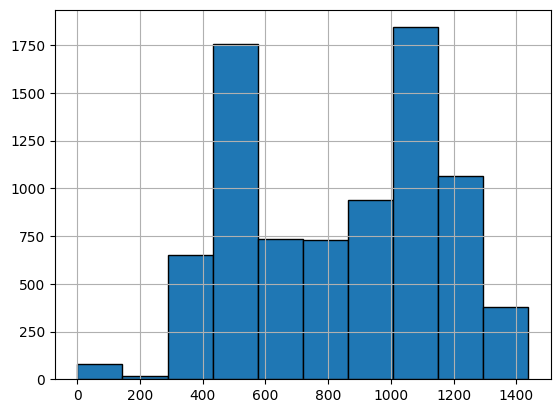

In [ ]:
locust_25['minutes_after_midnight'].hist(edgecolor='black')

<Axes: >

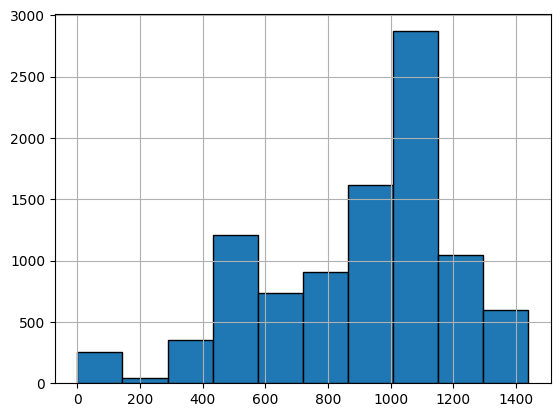

In [ ]:
amtrak_30['minutes_after_midnight'].hist(edgecolor='black')

<Axes: >

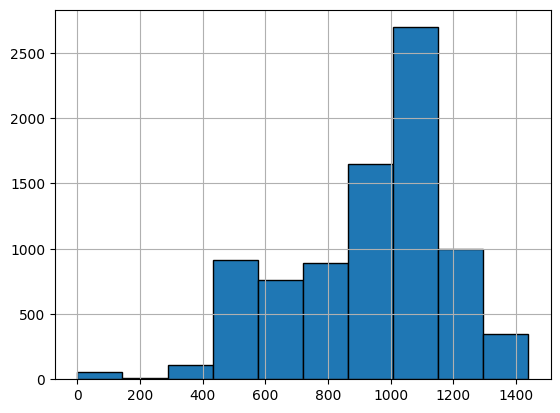

In [ ]:
locust_25_return['minutes_after_midnight'].hist(edgecolor='black')

<Axes: >

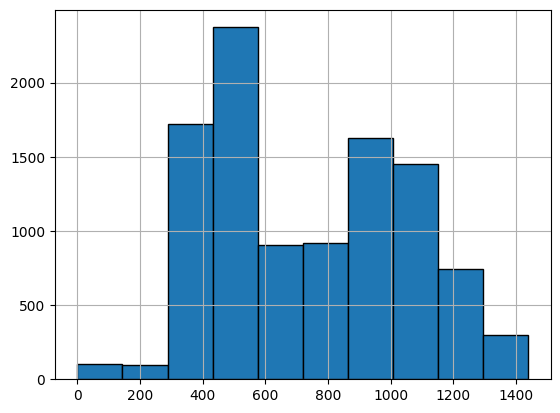

In [ ]:
amtrak_30_return['minutes_after_midnight'].hist(edgecolor='black')

In [ ]:
standard_bike = indego_2025_oneway[indego_2025_oneway['bike_type'] == 'standard']
electric_bike = indego_2025_oneway[indego_2025_oneway['bike_type'] == 'electric']

In [ ]:
indego_realstations['duration'].describe()

,duration
count,1.252675e+06
mean,1.566766e+01
std,4.483121e+01
min,1.000000e+00
25%,6.000000e+00
50%,1.000000e+01
75%,1.600000e+01
max,1.440000e+03


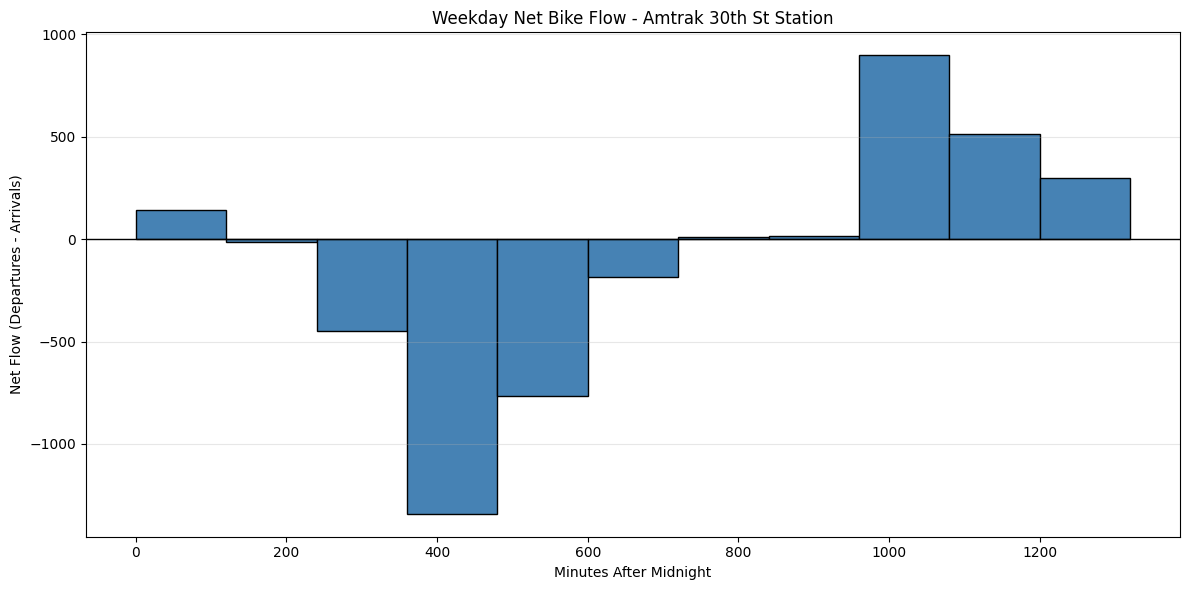

In [ ]:
import matplotlib.pyplot as plt
#Assisted by Claude
# Define bins
bins = np.arange(0, 1440, 120)

# Get histogram counts
departures, bin_edges = np.histogram(amtrak_30['minutes_after_midnight'], bins=bins)
arrivals, _ = np.histogram(amtrak_30_return['minutes_after_midnight'], bins=bins)

# Calculate net
net = departures - arrivals

# Plot
plt.figure(figsize=(12, 6))
plt.bar(bin_edges[:-1], net, width=np.diff(bin_edges),
        edgecolor='black', align='edge', color='steelblue')
plt.axhline(y=0, color='black', linestyle='-', linewidth=1)

plt.xlabel('Minutes After Midnight')
plt.ylabel('Net Flow (Departures - Arrivals)')
plt.title('Weekday Net Bike Flow - Amtrak 30th St Station')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

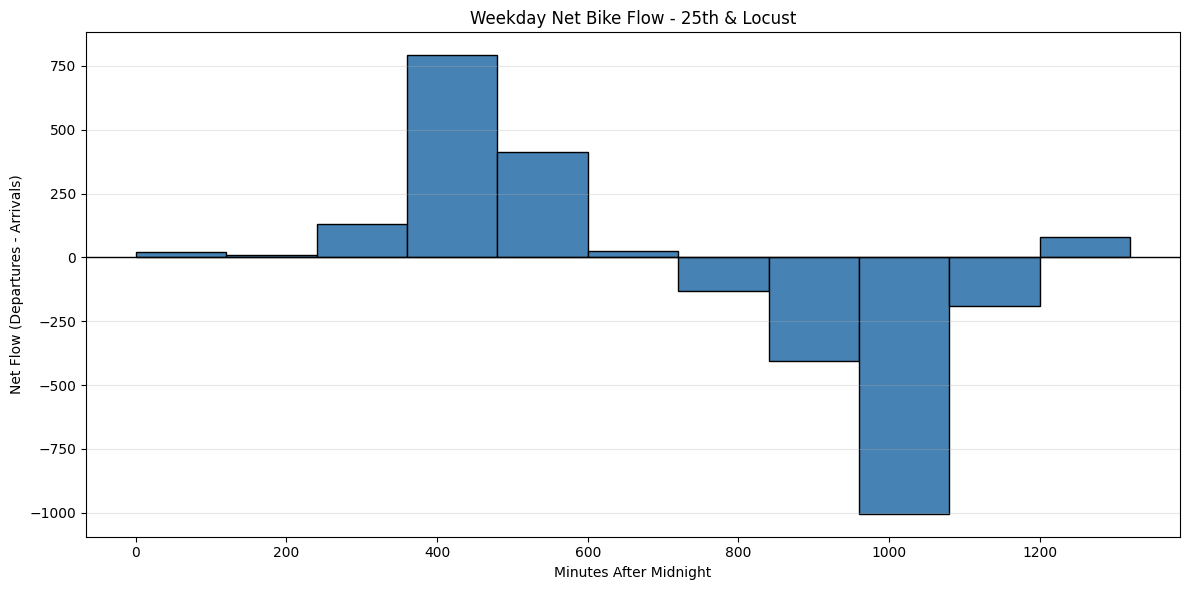

In [ ]:
bins = np.arange(0, 1440, 120)

# Get histogram counts
departures, bin_edges = np.histogram(locust_25['minutes_after_midnight'], bins=bins)
arrivals, _ = np.histogram(locust_25_return['minutes_after_midnight'], bins=bins)

# Calculate net
net = departures - arrivals

# Plot
plt.figure(figsize=(12, 6))
plt.bar(bin_edges[:-1], net, width=np.diff(bin_edges),
        edgecolor='black', align='edge', color='steelblue')
plt.axhline(y=0, color='black', linestyle='-', linewidth=1)

plt.xlabel('Minutes After Midnight')
plt.ylabel('Net Flow (Departures - Arrivals)')
plt.title('Weekday Net Bike Flow - 25th & Locust')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()